In [1]:
config_path = "config/params.yaml"
mode = "default"

In [2]:
# Parameters
config_path = "config/params.yaml"


# 05 — Validasi label

**Tujuan:** menilai arti dan kualitas label sesuai `docs/04`, memakai jam dev dan train saja.
Label jam studi tidak digabungkan dengan tabel fitur.

In [3]:
import json

import numpy as np
import polars as pl

from ghremoval.config import load_context
from ghremoval.github_client import GitHubClient
from ghremoval.labels import legacy_node_id, load_labels
from ghremoval.quality import Checks, wilson
from ghremoval.report import save_table
from ghremoval.runlog import RunLog
from ghremoval.secrets import load_token
from ghremoval.validate_labels import WebChecker, current_logins, ghost_probe, id_age_check, raw_scan, web_crosscheck
from ghremoval.viz import new_figure, save_figure

ctx = load_context(config_path)
run = RunLog("05_label_validation", ctx.paths.run_log, ctx.paths.root)
checks = Checks()
client = GitHubClient(load_token(ctx), ctx.p.project["user_agent"])
rng = np.random.default_rng(ctx.p.project["seed"])
scope_hours = [hour for hour, week in ctx.all_hours() if week in ("dev", "w0", "w1")]
labels = pl.concat([load_labels(ctx, "dev"), load_labels(ctx, "train")]).unique("actor_id").filter(pl.col("status") != "error")
hours = pl.read_parquet(ctx.paths.processed / "account_hour.parquet").filter(pl.col("week").is_in(["dev", "w0", "w1"]) & ~pl.col("is_app_bot"))
print("akun:", labels.height, "hilang:", int(labels["is_gone"].sum()))

akun: 528822 hilang: 11086


## 1. Tingkat hilang per stratum

In [4]:
first = hours.filter(pl.col("is_first_in_period")).join(labels.select("actor_id", "is_gone"), on="actor_id", how="inner").with_columns(pl.when(pl.col("week") == "dev").then(pl.lit("dev")).otherwise(pl.lit("train")).alias("set"))
rates = first.group_by(["set", "stratum"]).agg(pl.len().alias("n"), pl.col("is_gone").sum().alias("gone")).sort(["set", "stratum"])
rates = rates.with_columns(pl.struct("gone", "n").map_elements(lambda r: list(wilson(r["gone"], r["n"])), return_dtype=pl.List(pl.Float64)).alias("ci")).with_columns((pl.col("gone") / pl.col("n")).alias("rate"), pl.col("ci").list.get(0).alias("ci_low"), pl.col("ci").list.get(1).alias("ci_high")).drop("ci")
save_table(rates, "tab_base_rate_by_stratum", "Disappearance rate by activity stratum (observed label)")
rates

set,stratum,n,gone,rate,ci_low,ci_high
str,str,u32,u32,f64,f64,f64
"""dev""","""1""",33905,520,0.015337,0.014083,0.016701
"""dev""","""2-4""",22210,408,0.01837,0.016686,0.020221
"""dev""","""20+""",858,334,0.389277,0.357214,0.422328
"""dev""","""5-19""",7576,185,0.024419,0.021177,0.028143
"""train""","""1""",264387,5186,0.019615,0.019094,0.020151
"""train""","""2-4""",163353,3049,0.018665,0.01802,0.019333
"""train""","""20+""",2690,200,0.074349,0.065031,0.084882
"""train""","""5-19""",52749,1472,0.027906,0.026534,0.029346


## 2. ID numerik sebagai proksi usia

{'n': 5000, 'spearman': 0.9995107812684194, 'monotone_deciles': True}


[PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_id_vs_created.pdf'),
 PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_id_vs_created.png')]

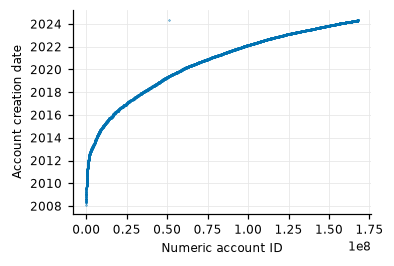

In [5]:
present = labels.filter((pl.col("status") == "present") & pl.col("created_at_api").is_not_null())
sample = present.sample(n=min(5000, present.height), seed=ctx.p.project["seed"]).sort("actor_id")
age = id_age_check(sample["actor_id"].to_numpy(), sample["created_at_api"])
print(age)
fig, ax = new_figure()
ax.plot(sample["actor_id"].to_numpy(), sample["created_at_api"].str.to_datetime("%Y-%m-%dT%H:%M:%SZ").to_numpy(), ".", ms=0.7, color="#0072B2")
ax.set_xlabel("Numeric account ID"); ax.set_ylabel("Account creation date")
save_figure(fig, "fig_id_vs_created")

[PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_rate_by_stratum_age.pdf'),
 PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_rate_by_stratum_age.png')]

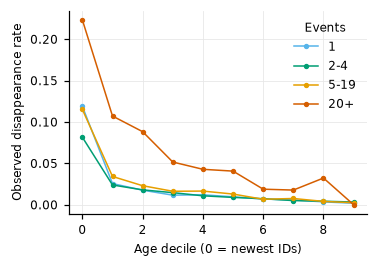

In [6]:
train = first.filter(pl.col("set") == "train")
edges = np.quantile(train["id_recency"].to_numpy(), np.linspace(0, 1, 11)[1:-1])
by_age = train.with_columns(pl.Series("age_decile", np.digitize(train["id_recency"].to_numpy(), edges))).group_by(["stratum", "age_decile"]).agg(pl.col("is_gone").mean().alias("rate"), pl.len().alias("n")).sort(["stratum", "age_decile"])
fig, ax = new_figure()
for stratum, color in zip(["1", "2-4", "5-19", "20+"], ["#56B4E9", "#009E73", "#E69F00", "#D55E00"]):
    part = by_age.filter(pl.col("stratum") == stratum)
    ax.plot(part["age_decile"].to_numpy(), part["rate"].to_numpy(), marker="o", ms=2.5, lw=1, label=stratum, color=color)
ax.set_xlabel("Age decile (0 = newest IDs)"); ax.set_ylabel("Observed disappearance rate"); ax.legend(title="Events")
save_figure(fig, "fig_rate_by_stratum_age")

## 3. Cek silang API dan halaman profil

Login hanya berada di memori. Output hanya memuat jumlah.

In [7]:
cfg = ctx.p.web_crosscheck
gone_ids = rng.choice(labels.filter(pl.col("is_gone"))["actor_id"].to_numpy(), min(cfg["n_gone"], int(labels["is_gone"].sum())), replace=False).tolist()
present_ids = rng.choice(present["actor_id"].to_numpy(), min(cfg["n_present"], present.height), replace=False).tolist()
gone_logins, _ = raw_scan(ctx, scope_hours, set(gone_ids))
now_logins = current_logins(client, present_ids, legacy_node_id)
crosscheck = web_crosscheck(WebChecker(ctx.p.project["user_agent"], cfg["sleep_seconds"]), gone_logins, now_logins)
print(crosscheck)
del gone_logins, now_logins

{'api_gone': {'404': 192, '200': 8}, 'api_present': {'200': 489, '504': 11}}


## 4. Probe `ghost`

In [8]:
gone_set = set(labels.filter(pl.col("is_gone"))["actor_id"].to_list())
control_pool = rng.choice(present["actor_id"].to_numpy(), min(4000, present.height), replace=False).tolist()
_, objects = raw_scan(ctx, scope_hours, gone_set | set(control_pool))
gone_objects = {a: u for a, u in objects.items() if a in gone_set}
control_candidates = [a for a in control_pool if a in objects]
control_objects = {a: objects[a] for a in control_candidates[:150]}
ghost_gone = ghost_probe(client, gone_objects, rng)
ghost_control = ghost_probe(client, control_objects, rng)
share_gone_with_objects = len(gone_objects) / max(len(gone_set), 1)
print("akun hilang:", ghost_gone, "porsi dengan objek:", round(share_gone_with_objects, 4))
print("kontrol:", ghost_control)

akun hilang: {'accounts': {'object_unavailable': 269, 'ghost': 237, 'other_author': 12}, 'objects': {'http_404': 413, 'ghost': 324, 'other_author': 25, 'http_403': 3, 'http_410': 4}, 'n_accounts': 518} porsi dengan objek: 0.0467
kontrol: {'accounts': {'attributed': 140, 'object_unavailable': 10}, 'objects': {'attributed': 201, 'http_404': 20}, 'n_accounts': 150}


## Ringkasan untuk Gerbang A

In [9]:
summary = {"id_age": age, "web_crosscheck": crosscheck, "ghost_gone": ghost_gone, "ghost_control": ghost_control, "share_gone_with_objects": share_gone_with_objects}
(ctx.paths.results / "label_validation.json").write_text(json.dumps(summary, indent=2) + "\n")
flat = [{"check": "spearman_id_created", "value": age["spearman"]}, {"check": "monotone_deciles", "value": float(age["monotone_deciles"])}]
for group, counts in crosscheck.items():
    flat += [{"check": f"web_{group}_{status}", "value": float(n)} for status, n in counts.items()]
save_table(pl.DataFrame(flat), "tab_label_validation", "Label validation summary")
present_web = crosscheck["api_present"]
pattern = present_web.get("404", 0) / max(sum(present_web.values()), 1)
print("porsi API 200 + web 404:", round(pattern, 4))
checks.add("gate_A_siap", True, "ringkasan tersedia")
checks.raise_if_failed()
print(run.finish(n_accounts=labels.height, n_gone=int(labels["is_gone"].sum())))

porsi API 200 + web 404: 0.0
[LULUS] gate_A_siap: ringkasan tersedia
{'notebook': '05_label_validation', 'finished_at_utc': '2026-11-10T10:57:06+00:00', 'git_commit': 'abfcd4a', 'duration_seconds': 3645.8, 'counts': {'n_accounts': 528822, 'n_gone': 11086}}
